# Price recommendation tool (prototype)

Give an arrival date of the 2026 season and the STD rooms still free that night. The notebook
returns the double-occupancy BAR recommended by the trained agents, and plots the price path of
one simulated season.

- **Policy:** the PPO seed ensemble from the final run (900k steps, elasticity 1.0). Each day it
  takes the median of the 5 seeds' greedy price levels, and it is the adopted policy. A table also
  shows the other ML model and Double DQN.
- **What the agents see:** the date's calendar features and demand forecast, and the rooms
  already taken tonight and tomorrow. Nothing else.
- **Reads:** `sim_data.pkl` and the checkpoints in `results_2026_<model>_e1.0_t900k/`. It stops if
  they don't come from the same world, and it writes no files.
- **Assumptions:**
  - The agents learned in the simulator, not from real bookings, under an assumed price
    response (elasticity 1.0).
  - One simulator step is one arrival date, so "rooms left" are the rooms free before that
    date's online sales.
  - The agents were trained with the hotel's real offline stays in place, so they never saw more
    rooms left than the hotel had on sale online that night.
  - Above the hotel's highest 2026 BAR the price response is extrapolated.

In [1]:
DATE = "2026-08-15"         # an arrival date of the 2026 season (3 Apr - 14 Oct)
ROOMS_LEFT = 10             # STD rooms still free tonight
ROOMS_LEFT_TOMORROW = None  # None: tomorrow only the real offline stays are taken
MODEL, ALGO = "rf", "ppo"   # headline policy: "rf" / "xgb" and "ppo" / "ddqn"

In [2]:
import os
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

from hotel_season_env import HotelEnv, PRICE_MULTIPLIERS
from rl_agent import (ALGOS, MODELS, MODEL_NAMES, SEASON, ELASTICITY, TIMESTEPS, SEEDS,
                      TEST_SEED0, RL_COLOURS, run_policy, run_batched, make_envs,
                      hotel_policy, greedy, ensemble)
from robustness import check_checkpoints, results_dir, env_kwargs_for

# The final run, as robustness.py reads it: fails unless its checkpoints come from sim_data.pkl
args = SimpleNamespace(season=SEASON, elasticity=ELASTICITY, timesteps=TIMESTEPS, seeds=SEEDS)
envs, best_fixed, seed_models, policies = {}, {}, {}, {}
for model in MODELS:
    best_fixed[model] = check_checkpoints(model, args)["best_fixed_multiplier"]
    envs[model] = HotelEnv(**env_kwargs_for(model, "nominal", args))
    for algo, (cls, _, _) in ALGOS.items():
        seed_models[model, algo] = [
            cls.load(os.path.join(results_dir(model, args), f"{algo}_seed{s}.zip"), device="cpu")
            for s in SEEDS]
        policies[model, algo] = ensemble(seed_models[model, algo])
%matplotlib inline
# (after the loading: rl_agent and ml_demand_model switch matplotlib to Agg when imported)
env = envs[MODEL]
print(f"Season {SEASON}: {env.dates[0].date()} to {env.dates[-1].date()}, {env.capacity} STD rooms, "
      f"reference BAR EUR {env.p_ref:.0f}, levels {PRICE_MULTIPLIERS[0]:.2f}-"
      f"{PRICE_MULTIPLIERS[-1]:.2f}x")

Season 2026: 2026-04-03 to 2026-10-14, 17 STD rooms, reference BAR EUR 160, levels 0.75-1.25x


In [3]:
def state(model, date, rooms_left, rooms_left_tomorrow=None):
    """The observation model's agents see on arrival date `date` with rooms_left
    STD rooms free tonight (and tomorrow; None: only the real offline stays)."""
    env = envs[model]
    dates = list(env.dates)
    if pd.Timestamp(date) not in dates:
        raise ValueError(f"{date} is not an arrival date of season {env.season} "
                         f"({env.dates[0].date()} to {env.dates[-1].date()})")
    for n in (rooms_left, rooms_left_tomorrow):
        if n is not None and not 0 <= n <= env.capacity:
            raise ValueError(f"Rooms left must be 0-{env.capacity}, not {n}")
    t = dates.index(pd.Timestamp(date))
    env.reset(seed=TEST_SEED0)                    # committed = the real offline stays
    env.t = t
    env.committed[t] = env.capacity - rooms_left
    if rooms_left_tomorrow is not None:
        env.committed[t + 1] = env.capacity - rooms_left_tomorrow
    return env._obs()


def recommend(date, rooms_left, rooms_left_tomorrow=None):
    env, name = envs[MODEL], f"{ALGOS[ALGO][2]} ensemble ({MODEL_NAMES[MODEL]})"
    obs = state(MODEL, date, rooms_left, rooms_left_tomorrow)
    t = env.t
    a = int(policies[MODEL, ALGO](obs[None])[0])
    print(f"{env.dates[t]:%a %d %b %Y}: {rooms_left} of {env.capacity} rooms left tonight "
          f"(the hotel had {env.online_avail[t]} on sale online, "
          f"{env.capacity - env.online_avail[t]} taken by offline stays)")
    if rooms_left > env.online_avail[t]:
        print(f"  !!! More rooms left than the hotel had on sale online that night: "
              "the agents never saw this state")
    print(f"\nRecommended BAR, {name}: EUR {env.prices[a]:.0f} "
          f"({PRICE_MULTIPLIERS[a]:.2f}x the reference EUR {env.p_ref:.0f})")
    print(f"  Hotel's real BAR that night: EUR {env.hotel_price[t]:.0f}; "
          f"best fixed price: EUR {best_fixed[MODEL] * env.p_ref:.0f} ({best_fixed[MODEL]:.2f}x)")
    if env.prices[a] > env.hotel_price.max():
        print(f"  Above the hotel's highest {env.season} BAR (EUR {env.hotel_price.max():.0f}): "
              "the price response is extrapolated there")

    rows = []
    for (model, algo), policy in policies.items():
        o, prices = state(model, date, rooms_left, rooms_left_tomorrow)[None], envs[model].prices
        seeds = [prices[int(greedy(m)(o)[0])] for m in seed_models[model, algo]]
        rows.append({"ML model": MODEL_NAMES[model], "RL": ALGOS[algo][2],
                     "ensemble BAR": prices[int(policy(o)[0])],
                     "seeds min": min(seeds), "seeds max": max(seeds)})
    print(f"\nEvery run of the final model ({len(SEEDS)} seeds each), EUR:")
    print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.0f}"))

    levels = np.arange(1, max(env.online_avail[t], rooms_left) + 1)
    actions = policies[MODEL, ALGO](np.stack([state(MODEL, date, n, rooms_left_tomorrow)
                                              for n in levels]))
    print(f"\nWhat if, {name}, same date, other rooms left tonight:")
    print(pd.DataFrame({"rooms left": levels, "multiplier": np.array(PRICE_MULTIPLIERS)[actions],
                        "BAR (EUR)": env.prices[actions]}).set_index("rooms left").T
          .to_string(float_format=lambda v: f"{v:.2f}" if v < 10 else f"{v:.0f}"))

In [4]:
recommend(DATE, ROOMS_LEFT, ROOMS_LEFT_TOMORROW)

Sat 15 Aug 2026: 10 of 17 rooms left tonight (the hotel had 9 on sale online, 8 taken by offline stays)
  !!! More rooms left than the hotel had on sale online that night: the agents never saw this state

Recommended BAR, PPO ensemble (ML1 RF): EUR 200 (1.25x the reference EUR 160)
  Hotel's real BAR that night: EUR 160; best fixed price: EUR 184 (1.15x)
  Above the hotel's highest 2026 BAR (EUR 177): the price response is extrapolated there

Every run of the final model (5 seeds each), EUR:
ML model         RL  ensemble BAR  seeds min  seeds max
  ML1 RF        PPO           200        200        200
  ML1 RF Double DQN           200        184        200
 ML2 XGB        PPO           200        192        200
 ML2 XGB Double DQN           192        184        200

What if, PPO ensemble (ML1 RF), same date, other rooms left tonight:
rooms left   1    2    3    4    5    6    7    8    9    10
multiplier 1.25 1.25 1.25 1.25 1.25 1.25 1.25 1.25 1.25 1.25
BAR (EUR)   200  200  200  200 

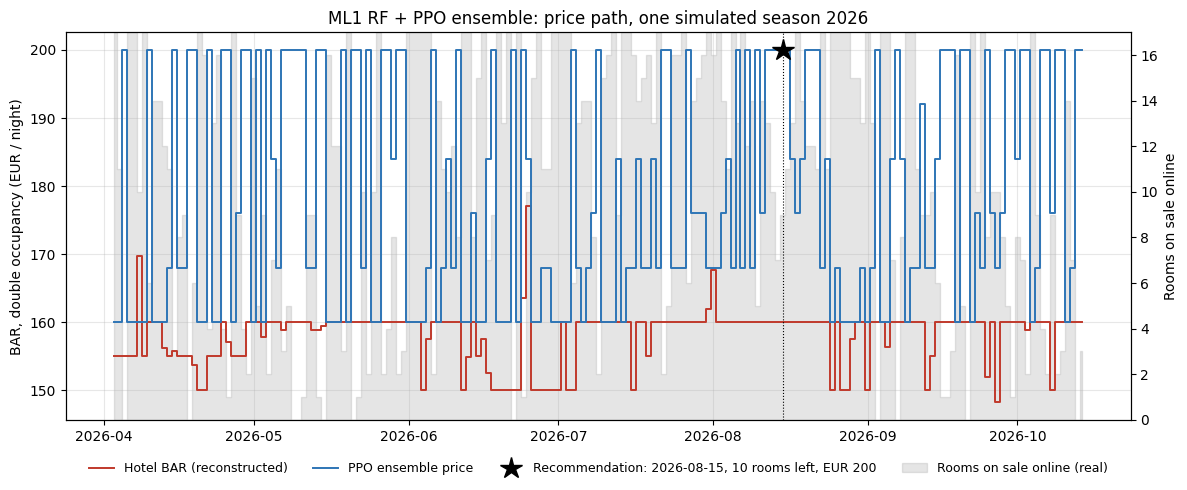

In [5]:
# Price path of one simulated test season (the season of results_*/price_path.png)
env, name = envs[MODEL], f"{ALGOS[ALGO][2]} ensemble"
hotel_path = run_policy(env, hotel_policy, n=1, record_path=True)[1]
agent_path = run_batched(make_envs(env_kwargs_for(MODEL, "nominal", args), 1),
                         policies[MODEL, ALGO], TEST_SEED0, record_path=True)[1]
price = env.prices[int(policies[MODEL, ALGO](state(MODEL, DATE, ROOMS_LEFT,
                                                    ROOMS_LEFT_TOMORROW)[None])[0])]

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.step(hotel_path["date"], hotel_path["price"], where="mid", color="#C0392B",
         lw=1.4, label="Hotel BAR (reconstructed)")
ax1.step(agent_path["date"], agent_path["price"], where="mid",
         color=RL_COLOURS[list(ALGOS).index(ALGO)], lw=1.4, label=f"{name} price")
ax1.axvline(pd.Timestamp(DATE), color="black", lw=0.8, ls=":")
ax1.plot(pd.Timestamp(DATE), price, "k*", ms=16,
         label=f"Recommendation: {DATE}, {ROOMS_LEFT} rooms left, EUR {price:.0f}")
ax1.set_ylabel("BAR, double occupancy (EUR / night)")
ax2 = ax1.twinx()
ax2.fill_between(env.dates, env.online_avail, step="mid", color="grey", alpha=0.2,
                 label="Rooms on sale online (real)")
ax2.set_ylabel("Rooms on sale online")
ax2.set_ylim(0, env.capacity)
ax2.yaxis.set_major_locator(MaxNLocator(integer=True))
ax1.set_zorder(ax2.get_zorder() + 1); ax1.patch.set_visible(False)   # prices over the shading
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=4,
           fontsize=9, frameon=False)
ax1.set_title(f"{MODEL_NAMES[MODEL]} + {name}: price path, one simulated season {SEASON}")
ax1.grid(alpha=0.3)
plt.tight_layout(); plt.show()